Expected Threat (xT) assigns a value to a pitch location according to the probability of eventually scoring from a possession that starts in that location, under the actions and transitions represented in the model [@singh2018xt]. Unlike expected goals (xG), which evaluates a shot, xT values positions before a shot occurs. A location far from goal can therefore have positive value if possession can progress towards more promising locations.

The xT surface is a **location-based** estimate: it summarizes typical outcomes in the event data and does not represent the particular players, defensive pressure or available passing options of an individual tracking frame. PRESS uses the fitted xT grid as a spatial input, not as a substitute for its state-dependent action models.

## Mathematical formulation

Divide the pitch into spatial bins indexed by $i$. In the project formulation, a possession in bin $i$ can result in a shot, a successful pass, a successful carry, or a loss of possession. The value satisfies the Bellman equation

$$
\mathrm{xT}_i = p_{\mathrm{shot},i}p_{\mathrm{goal},i} + p_{\mathrm{pass},i}\sum_j T^{\mathrm{pass}}_{ij}\mathrm{xT}_j + p_{\mathrm{carry},i}\sum_j T^{\mathrm{carry}}_{ij}\mathrm{xT}_j.
$$

Here $p_{\mathrm{shot},i}$ is the probability of a shot and $p_{\mathrm{goal},i}$ is its conditional scoring probability. The coefficients $p_{\mathrm{pass},i}$ and $p_{\mathrm{carry},i}$ include the probability of **successful continuation** through the respective action; they are not simply the probabilities of choosing pass or carry in action selection. $T^{\mathrm{pass}}_{ij}$ and $T^{\mathrm{carry}}_{ij}$ describe destination bins conditional on a successful continuation. Possession loss contributes zero future scoring value, so the displayed branch probabilities need not sum to one.

The original xT formulation [@singh2018xt] groups successful ball progression into a move branch. Separating pass and carry, with an explicit zero-value loss outcome, is the project-specific formulation described here. Starting from zero values, the equation can be iterated until the grid converges.

## Estimation from event data

The probabilities in the Bellman equation are estimated from event data and are not learned as a single supervised prediction target. Events are assigned to pitch bins; shot outcomes, successful continuations, and their destinations supply the local probabilities and transition distributions. The fitted value surface then follows from the Bellman iteration.

The production surface uses the archived event tables from all **ten matches**: **9,071 within-possession displacements, 6,355 completed passes, 212 shots (23 goals), and 2,214 terminal losses**. A displacement records movement from the matched start to the matched end of individual control; these are not the canonical one-second carries of the ball-drive classifier. Passes connect release to matched reception. Shot and loss locations use the end of individual control. Coordinates are oriented so the team in possession attacks from left to right. These counts come from the archived event cohort, which is more permissive than the verified pass-probability cohort: it includes goalkeeper passers and passes later excluded there by the association and flight-duration checks, and it omits completions whose origin or destination falls outside the fixed 105 × 68 m grid.

For each origin cell, counts of the four event types share a common denominator. Pass and carry destination counts are smoothed separately, then normalized into transition rows; unseen origins have a uniform destination distribution. Shot and goal counts are smoothed separately and then divided, so the raw scoring proportion is never smoothed directly. Gaussian bandwidths were selected from 0, 3, 5, 8, 12 and 18 m by leave-one-match-out cross-validation, separately for each component: the negative log-likelihood of the observed destination under the smoothed transition density for passes and carries, and the Bernoulli cross-entropy of the goal outcome for shots. Scores are aggregated with weights proportional to the number of events, and the largest bandwidth within one paired-match standard error of the best score is chosen. The ten-match fit uses **8 m for passes, 5 m for carries and 5 m for shots**. Empty-origin action probabilities are zero. Bellman iteration starts at zero and stops when the maximum change is below $10^{-12}$; the saved production fit converged in 139 iterations.

This is the all-match **production** surface, also embedded in the deployed pass-selection and action-selection models. The predictive benchmarks use xT fitted only on their corresponding training matches. [Production provenance](../../../docs/expected-threat-vignette-provenance.json).

## Spatial discretization and binning

Binning determines the spatial resolution of the fitted value function. Smaller bins preserve more local variation but provide fewer events per cell and sparser transition estimates; larger bins stabilize estimates but can obscure meaningful spatial structure. Smoothing can reduce sampling noise, at the cost of spatial detail.

We use **10 × 6 cells** on the 105 × 68 m pitch: each cell measures **10.5 × 11.33 m**. With only ten matches and 212 shots, a much finer surface would have sparse local scoring estimates and transition rows. The resolution review compared 8 × 5, 10 × 6, 12 × 8 and 16 × 12, using the same archived event tables for every grid and selecting smoothing within training matches.

| Grid | Cells without shots | Cells with fewer than five shots | Held-out shot-outcome CE | Held-out shot-outcome Brier | Mean map SD |
|---|---:|---:|---:|---:|---:|
| 8 × 5 | 30 / 40 | 34 / 40 | 0.3431 | 0.0968 | 0.00250 |
| **10 × 6** | **47 / 60** | **50 / 60** | **0.3028** | **0.0911** | **0.00248** |
| 12 × 8 | 76 / 96 | 84 / 96 | 0.3078 | 0.0903 | 0.00309 |
| 16 × 12 | 159 / 192 | 174 / 192 | 0.3123 | 0.0898 | 0.00338 |

The 10 × 6 grid has the lowest shot-outcome CE and the lowest mean variability among the five training-fold surfaces, and it is the resolution retained. The 12 × 8 and 16 × 12 grids have slightly lower Brier scores, with higher CE and more variable surfaces. Shot-outcome CE evaluates the goal-given-shot component and not the complete future-possession xT prediction. [Coverage](../../../data/examples/expected_threat/coverage.csv), [component scores](../../../data/examples/expected_threat/metrics.csv), and [map stability](../../../data/examples/expected_threat/map_stability.csv).

## Fitted xT surface

The heatmap shows the exact **production xT values fitted on all ten matches**, with the same 10 × 6 cells and no visual interpolation. The saved array has shape `(n_x, n_y)`; its first axis is longitudinal, and its second axis runs from the bottom to the top of the pitch. Both the display and `get_xt_values` use this convention, with attack from left to right.


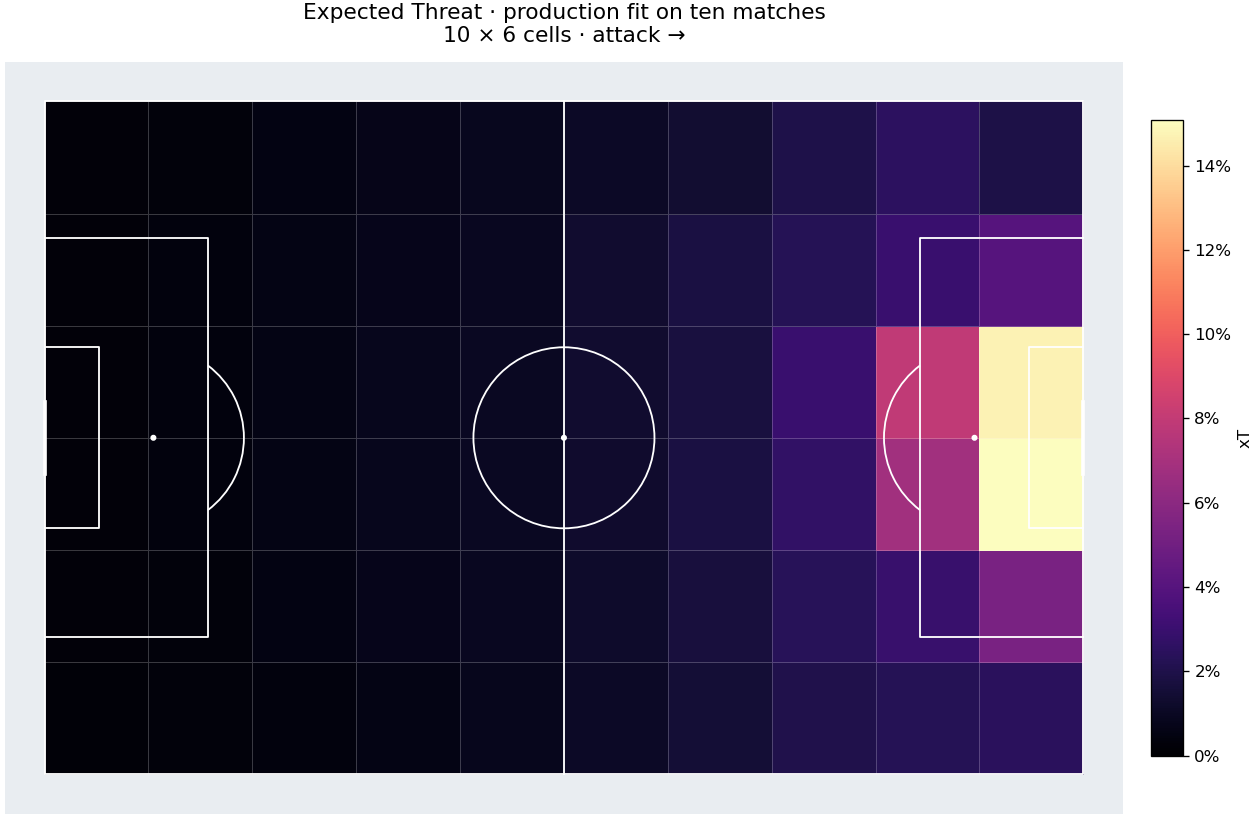

In [3]:
from pathlib import Path
import sys
import json
import numpy as np
import matplotlib.pyplot as plt

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "_quarto.yml").is_file())
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
from scripts.build_xt_vignette_figures import plot_xt_surface

# The actual surface distributed with the pretrained choice model.
artifact = json.loads((root / "PRESS/utils/data/pass_selection_model.json").read_text())
xt_grid = np.asarray(artifact["xt_grid"], dtype=float)
fig, ax = plot_xt_surface(xt_grid)
plt.show()


## Using xT in PRESS

PRESS expects an xT grid with shape `(n_x, n_y)` and uses centred pitch coordinates. The helper `get_xt_values` evaluates locations for both teams, accounting for attacking direction. This example uses the fitted grid loaded above.


In [5]:
from PRESS.utils.state import get_xt_values

targets = np.array([[-35., -17.], [0., 17.], [35., -17.]])
team_xt, opponent_xt = get_xt_values(targets, 'left_to_right', xt_grid)
print('xT grid (n_x, n_y):', xt_grid.shape)
print('team xT:', team_xt)
print('opponent xT:', opponent_xt)


xT grid (n_x, n_y): (10, 6)
team xT: [0.00350905 0.01322827 0.02891891]
opponent xT: [0.02993278 0.01231441 0.00397719]
